mini project 2

In [ ]:
import numpy as np


class MicroGrid:
    """A class representing a micro-grid energy distribution system.

    Models the system of linear equations:
        3x + 2y = D1  (Daytime load)
        4x +  y = D2  (Critical-equipment load)

    where:
        x: Energy drawn from solar panels (kWh)
        y: Energy drawn from batteries (kWh)
    """

    def __init__(self, A: np.ndarray = None):
        if A is None:
            # Default coefficient matrix based on system constraints
            self.A = np.array([[3.0, 2.0], [4.0, 1.0]], dtype=float)
        else:
            self.A = np.array(A, dtype=float)

    def solve_day(self, d1: float, d2: float) -> tuple[float, float]:
        """Solves for solar panel (x) and battery (y) energy draws for given daily loads.

        Parameters:
            d1 (float): Daytime load demand in kWh.
            d2 (float): Critical-equipment load demand in kWh.

        Returns:
            tuple[float, float]: (x_solar, y_battery) required in kWh.

        Raises:
            ValueError: If inputs are invalid or lead to physically impossible (negative) draws.
            numpy.linalg.LinAlgError: If the coefficient matrix is singular/non-invertible.
        """
        # Validate input types and non-negative demand values
        if d1 < 0 or d2 < 0:
            raise ValueError(
                f"Demands must be non-negative. Received D1={d1}, D2={d2}."
            )

        # Construct demand vector B
        B = np.array([d1, d2], dtype=float)

        # Check matrix determinant before attempting inversion
        det = np.linalg.det(self.A)
        if np.isclose(det, 0):
            raise np.linalg.LinAlgError(
                "Coefficient matrix is singular and cannot be inverted."
            )

        # Solve system A * [x, y]^T = B
        x_solar, y_battery = np.linalg.solve(self.A, B)

        # Feasibility check: energy draw cannot be negative
        if x_solar < 0 or y_battery < 0:
            raise ValueError(
                f"Infeasible demand combination (D1={d1}, D2={d2}). "
                f"Calculated draws (x={x_solar:.2f}, y={y_battery:.2f}) violate non-negativity bounds (x >= 0, y >= 0). "
                f"Ensure 0.75 * D2 <= D1 <= 2.0 * D2."
            )

        return float(x_solar), float(y_battery)


# Example usage:
if __name__ == "__main__":
    grid = MicroGrid()

    # Valid scenario: D1 = 100 kWh, D2 = 110 kWh
    try:
        x, y = grid.solve_day(d1=100, d2=110)
        print(f"Required Solar Power (x): {x:.2f} kWh")
        print(f"Required Battery Power (y): {y:.2f} kWh")
    except ValueError as e:
        print(f"Error: {e}")

Required Solar Power (x): 24.00 kWh
Required Battery Power (y): 14.00 kWh


explanation from check....

In [ ]:
import numpy as np

# Coefficient matrix A for the micro-grid system:
# 3x + 2y = D1
# 4x + 1y = D2
A = np.array([[3.0, 2.0],
              [4.0, 1.0]])

# 1. Compute Determinant
det_A = np.linalg.det(A)

# 2. Compute Condition Number (L2 norm by default)
cond_A = np.linalg.cond(A)

print(f"Determinant: {det_A}")
print(f"Condition Number: {cond_A:.4f}")

Determinant: -4.999999999999999
Condition Number: 5.8284


1. Mathematical ComputationFor the coefficient matrix $A = \begin{pmatrix} 3 & 2 \\ 4 & 1 \end{pmatrix}$:Determinant:$$\det(A) = (3 \times 1) - (2 \times 4) = 3 - 8 = -5$$Condition Number ($\kappa(A)$):$$\kappa(A) = \Vert{}A\Vert{} \cdot \Vert{}A^{-1}\Vert{} \approx 5.83$$

2. Explanation & Meaning for the Micro-Grid SystemDeterminant ($\det(A) = -5 \neq 0$):Meaning: Because the determinant is non-zero, matrix $A$ is invertible (non-singular).System Impact:
There is a unique solution $(x, y)$ for any combination of demands $(D_1, D_2)$. The two equations are linearly independent, meaning the daytime load constraint and critical-equipment constraint provide distinct, non-redundant information.Condition Number ($\kappa(A) \approx 5.83$):Meaning:

The condition number measures how sensitive the solution $(x, y)$ is to small variations or measurement errors in the input demands $(D_1, D_2)$.System Impact:
A condition number close to $1$ (and well below $100$) means the system is extremely well-conditioned and stable. Measurement noise or sensor inaccuracies in daily load monitoring will not produce amplified errors in the required solar panel ($x$) or battery ($y$) energy calculations.

3. What You Need to Do Before ProceedingBefore integrating these components into your broader workflow or answering the remaining parts of your assignment/project, complete the following steps:
Integrate Well-Posedness Checks into Code:Update your MicroGrid class or driver script to verify that:$\det(A) \neq 0$ (confirming a unique solution exists).$\kappa(A)$ is low (confirming numerical stability).Verify Physical Feasibility Bounds:Ensure your pipeline checks the demand inputs $(D_1, D_2)$ against the non-negativity constraint ($x \ge 0, y \ge 0$):$$\frac{3}{4} D_2 \le D_1 \le 2 D_2$$If real-world demands fall outside this window, flag them as physically unachievable with solar and battery power alone.Format Output Data Structures:Ensure your solve_day(d1, d2) method returns data in the format needed downstream (e.g., a dictionary {"solar_kwh": x, "battery_kwh": y} or standard NumPy array) for easy feeding into plotting functions, reporting tools, or time-series simulations

In [ ]:
import sys
import numpy as np
import pandas as pd


class MicroGrid:
    """MicroGrid solver for solar and battery energy draws given demand constraints.

    System of Equations:
        3x + 2y = D1  (Daytime load, kWh)
        4x + 1y = D2  (Critical-equipment load, kWh)
    """

    def __init__(self, A: np.ndarray = None):
        if A is None:
            self.A = np.array([[3.0, 2.0], [4.0, 1.0]], dtype=float)
        else:
            self.A = np.array(A, dtype=float)

        # Check well-posedness
        self.det = np.linalg.det(self.A)
        self.cond = np.linalg.cond(self.A)

        if np.isclose(self.det, 0):
            raise np.linalg.LinAlgError(
                "Coefficient matrix is singular and cannot be inverted."
            )

    def solve_day(self, d1: float, d2: float) -> tuple[float, float]:
        """Solves for solar panel draw (x) and battery draw (y) for a single day."""
        if d1 < 0 or d2 < 0:
            raise ValueError(
                f"Demands must be non-negative. Received D1={d1}, D2={d2}."
            )

        B = np.array([d1, d2], dtype=float)
        x_solar, y_battery = np.linalg.solve(self.A, B)

        # Physical feasibility check: energy draw cannot be negative
        if x_solar < 0 or y_battery < 0:
            raise ValueError(
                f"Infeasible demand combination (D1={d1:.2f}, D2={d2:.2f}). "
                f"Calculated draws (x={x_solar:.2f}, y={y_battery:.2f}) violate non-negativity bounds (x >= 0, y >= 0). "
                f"Ensure valid bounds: 0.75 * D2 <= D1 <= 2.0 * D2."
            )

        return float(x_solar), float(y_battery)



# MODE A: INTERACTIVE INPUT WITH ROBUST VALIDATION

def get_valid_float(prompt: str) -> float:
    """Prompts user for a numeric input until a valid non-empty, non-negative float is entered."""
    while True:
        raw = input(prompt).strip()

        # Reject empty string
        if not raw:
            print("  ❌ Input cannot be empty. Please enter a valid number.")
            continue

        # Reject non-numeric inputs
        try:
            val = float(raw)
        except ValueError:
            print("  ❌ Non-numeric input detected. Please enter a number.")
            continue

        # Reject negative values
        if val < 0:
            print(
                f"  ❌ Value cannot be negative ({val}). Demand must be >= 0."
            )
            continue

        return val


def run_interactive_mode(grid: MicroGrid):
    """Executes Mode A: User interactive prompt."""
    print("\n--- Mode (a): Interactive Single-Day Input ---")
    d1 = get_valid_float("Enter Daytime Load D1 (kWh): ")
    d2 = get_valid_float("Enter Critical Load D2 (kWh): ")

    try:
        x, y = grid.solve_day(d1, d2)
        print("\n" + "=" * 40)
        print(f"  Daytime Load (D1):  {d1:.2f} kWh")
        print(f"  Critical Load (D2): {d2:.2f} kWh")
        print("-" * 40)
        print(f"  Solar Panel Draw (x): {x:.2f} kWh")
        print(f"  Battery Draw (y):     {y:.2f} kWh")
        print("=" * 40 + "\n")
    except ValueError as e:
        print(f"\n❌ Feasibility Error: {e}\n")



# MODE B: CSV FILE BATCH PROCESSING (30 DAYS)

def run_csv_mode(
    grid: MicroGrid,
    csv_filepath: str = "kasese_microgrid_daily_demand.csv",
):
    """Executes Mode B: Loads 30 days of demand data from CSV and calculates draws."""
    print(f"\n--- Mode (b): Loading CSV File '{csv_filepath}' ---")

    try:
        df = pd.read_csv(csv_filepath)
    except FileNotFoundError:
        print(
            f"❌ File '{csv_filepath}' not found. Please verify the filename and path."
        )
        return

    # Column verification
    required_cols = ["d1_daytime_load_kwh", "d2_critical_load_kwh"]
    if not all(col in df.columns for col in required_cols):
        print(
            f"❌ CSV must contain columns: {required_cols}. Found: {list(df.columns)}"
        )
        return

    # Solve row by row with error logging for infeasible rows
    sol_x, sol_y, status = [], [], []

    for idx, row in df.iterrows():
        d1 = row["d1_daytime_load_kwh"]
        d2 = row["d2_critical_load_kwh"]

        try:
            x, y = grid.solve_day(d1, d2)
            sol_x.append(round(x, 2))
            sol_y.append(round(y, 2))
            status.append("Valid")
        except ValueError as e:
            sol_x.append(np.nan)
            sol_y.append(np.nan)
            status.append("Infeasible")

    df["solved_solar_x_kwh"] = sol_x
    df["solved_battery_y_kwh"] = sol_y
    df["status"] = status

    print(f"\nSuccessfully processed {len(df)} records!")
    print("\nFirst 10 Days Preview:")
    print(
        df[
            [
                "date",
                "day_of_week",
                "d1_daytime_load_kwh",
                "d2_critical_load_kwh",
                "solved_solar_x_kwh",
                "solved_battery_y_kwh",
                "status",
            ]
        ]
        .head(10)
        .to_string(index=False)
    )

    # Optional: Save processed output
    output_filename = "kasese_microgrid_solved_30days.csv"
    df.to_csv(output_filename, index=False)
    print(f"\nSaved full results to '{output_filename}'.")



# MAIN ROUTER

if __name__ == "__main__":
    grid = MicroGrid()

    print("==================================================")
    print("      KASESE MICRO-GRID ENERGY CALCULATOR         ")
    print("==================================================")
    print("Matrix Determinant:", grid.det)
    print(f"Condition Number:  {grid.cond:.4f} (Well-Posed)")
    print("--------------------------------------------------")
    print("Select Input Mode:")
    print("  [1] Interactive input ()")
    print("  [2] Load 30-day demand from CSV file")

    mode = input("\nEnter choice (1 or 2): ").strip()

    if mode == "1":
        run_interactive_mode(grid)
    elif mode == "2":
        csv_file = (
            input(
                "Enter CSV filename [default: kasese_microgrid_daily_demand.csv]: "
            ).strip()
            or "kasese_microgrid_daily_demand.csv"
        )
        run_csv_mode(grid, csv_file)
    else:
        print("❌ Invalid selection. Exiting program.")

      KASESE MICRO-GRID ENERGY CALCULATOR         
Matrix Determinant: -4.999999999999999
Condition Number:  5.8284 (Well-Posed)
--------------------------------------------------
Select Input Mode:
  [1] Interactive input ()
  [2] Load 30-day demand from CSV file

Enter choice (1 or 2): 1

--- Mode (a): Interactive Single-Day Input ---
Enter Daytime Load D1 (kWh): 105
Enter Critical Load D2 (kWh): 100

  Daytime Load (D1):  105.00 kWh
  Critical Load (D2): 100.00 kWh
----------------------------------------
  Solar Panel Draw (x): 19.00 kWh
  Battery Draw (y):     24.00 kWh



part b
how i have generated the dataset

In [ ]:
import numpy as np
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

# Generate 30 days of data
num_days = 30
dates = pd.date_range(start="2026-09-01", periods=num_days, freq="D")

# Base demand levels (kWh)
base_d2 = 110.0  # Critical-equipment load baseline
base_d1 = 100.0  # Daytime load baseline

# Weekly pattern: higher demand on weekdays (Mon-Fri), lower on weekends (Sat-Sun)
# Dayofweek: Mon=0, Tue=1, Wed=2, Thu=3, Fri=4, Sat=5, Sun=6
day_of_week = dates.dayofweek
weekly_factor = np.where(day_of_week < 5, 1.05, 0.88)

# Generate D1 and D2 with weekly pattern + Gaussian noise
noise_d1 = np.random.normal(0, 3.5, size=num_days)
noise_d2 = np.random.normal(0, 4.0, size=num_days)

D1 = base_d1 * weekly_factor + noise_d1
D2 = base_d2 * weekly_factor + noise_d2

# Ensure physical feasibility bounds: 0.75 * D2 <= D1 <= 2.0 * D2
# Clip D1 slightly if needed to guarantee feasibility
D1 = np.clip(D1, 0.76 * D2, 1.95 * D2)

# Solve for Solar (x) and Battery (y) energy draws using closed-form solutions:
# x = (2*D2 - D1) / 5
# y = (4*D1 - 3*D2) / 5
x_solar = (2 * D2 - D1) / 5.0
y_battery = (4 * D1 - 3 * D2) / 5.0

# Create DataFrame
df_microgrid = pd.DataFrame({
    "date": dates.strftime("%Y-%m-%d"),
    "day_of_week": dates.strftime("%A"),
    "d1_daytime_load_kwh": np.round(D1, 2),
    "d2_critical_load_kwh": np.round(D2, 2),
    "solar_draw_x_kwh": np.round(x_solar, 2),
    "battery_draw_y_kwh": np.round(y_battery, 2)
})

# Save to CSV
csv_filename = "kasese_microgrid_daily_demand.csv"
df_microgrid.to_csv(csv_filename, index=False)

print(f"CSV generated successfully: {csv_filename}")
print("\nFirst 10 rows preview:")
print(df_microgrid.head(10).to_string(index=False))

CSV generated successfully: kasese_microgrid_daily_demand.csv

First 10 rows preview:
      date day_of_week  d1_daytime_load_kwh  d2_critical_load_kwh  solar_draw_x_kwh  battery_draw_y_kwh
2026-09-01     Tuesday               106.74                113.09             23.89               17.53
2026-09-02   Wednesday               104.52                122.91             28.26                9.87
2026-09-03    Thursday               107.27                115.45             24.73               16.55
2026-09-04      Friday               110.33                111.27             22.44               21.50
2026-09-05    Saturday                87.18                100.09             22.60                9.69
2026-09-06      Sunday                87.18                 91.92             19.33               14.59
2026-09-07      Monday               110.53                116.34             24.43               18.62
2026-09-08     Tuesday               107.69                107.66             21.5

part 3
run the above section first, so that it can load the file(cv).

In [ ]:
import numpy as np
import pandas as pd
from scipy.linalg import solve
import timeit

# 1. Load the 30-day demand dataset
df = pd.read_csv("kasese_microgrid_daily_demand.csv")
d1 = df["d1_daytime_load_kwh"].values
d2 = df["d2_critical_load_kwh"].values

# Coefficient matrix A (3x + 2y = D1, 4x + y = D2)
A = np.array([[3.0, 2.0], [4.0, 1.0]], dtype=float)



# Approach 1: Python Loop

def solve_loop():
    x_list, y_list = [], []
    for i in range(len(d1)):
        b = np.array([d1[i], d2[i]])
        sol = solve(A, b)
        x_list.append(sol[0])
        y_list.append(sol[1])
    return np.array(x_list), np.array(y_list)



# Approach 2: Vectorized Call (Pass 2x30 Right-Hand Side Matrix B)

# Construct 2x30 RHS matrix where Row 0 = D1 and Row 1 = D2
B_matrix = np.vstack([d1, d2])  # Shape: (2, 30)


def solve_vectorized():
    # Solves A * X = B in a single operation; X has shape (2, 30)
    X = solve(A, B_matrix)
    return X[0, :], X[1, :]


# Verify mathematical equivalence
x_loop, y_loop = solve_loop()
x_vec, y_vec = solve_vectorized()
np.testing.assert_allclose(x_loop, x_vec)
np.testing.assert_allclose(y_loop, y_vec)


# Timeit Benchmarking (1,000 runs)

n_runs = 1000
t_loop = (
    timeit.timeit(solve_loop, number=n_runs) / n_runs * 1e6
)  # Microseconds
t_vec = (
    timeit.timeit(solve_vectorized, number=n_runs) / n_runs * 1e6
)  # Microseconds

print(f"Python Loop Time:       {t_loop:.2f} µs")
print(f"Vectorized Call Time:   {t_vec:.2f} µs")
print(f"Speedup Factor:         {t_loop / t_vec:.2f}x faster")

Python Loop Time:       2210.97 µs
Vectorized Call Time:   99.70 µs
Speedup Factor:         22.18x faster


**Explanation**

Commentary on Performance DifferencesPython Overhead Reduction:In the iterative approach, Python enters and exits the scipy.linalg.solve function 30 distinct times, incurring repeated function call overhead, Python-to-C memory translation, and input validation checks for every iteration.

The vectorized approach passes the entire matrix B ($2 \times 30$) in a single call, executing the bulk of the work in compiled BLAS/LAPACK C code.LU Decomposition Reuse:When scipy.linalg.solve(A, B) receives a matrix B with multiple columns, it performs the LU decomposition of the coefficient matrix $A = P L U$ only once ($O(n^3)$ operations, where $n=2$).

It then applies forward/backward substitution ($O(n^2)$ operations) across all 30 column vectors simultaneously. In contrast, the loop redundantly recalculates the LU decomposition of $A$ 30 separate times.Scalability Impact:While a ~3x speedup is notable for 30 days, the performance gap grows exponentially as dataset size increases (e.g., hourly multi-year data with thousands of time steps), making vectorization essential for production energy system modeling.

this segment loads the dataset

In [ ]:
import numpy as np
import pandas as pd
from scipy.optimize import nnls
from scipy.linalg import solve

# Load dataset
df = pd.read_csv("kasese_microgrid_daily_demand.csv")

# Inject 3 infeasible days to test robust detection and handling
# Day 5: D1 far too low relative to D2 -> y < 0 in unconstrained linear solve
# Day 15: D1 far too high relative to D2 -> x < 0 in unconstrained linear solve
# Day 25: Both D1 and D2 small/unbalanced
df_test = df.copy()
df_test.loc[4, 'd1_daytime_load_kwh'] = 50.0   # D1=50, D2=100.09 -> D1 < 0.75*D2
df_test.loc[14, 'd1_daytime_load_kwh'] = 250.0 # D1=250, D2=116.34 -> D1 > 2.0*D2

A = np.array([[3.0, 2.0],
              [4.0, 1.0]], dtype=float)

results = []

for idx, row in df_test.iterrows():
    d1 = row['d1_daytime_load_kwh']
    d2 = row['d2_critical_load_kwh']
    b = np.array([d1, d2], dtype=float)

    # 1. Unconstrained Standard Linear Solve
    x_raw, y_raw = solve(A, b)
    is_infeasible = (x_raw < 0) or (y_raw < 0)

    # 2. Strategy 1: Non-Negative Least Squares (scipy.optimize.nnls)
    sol_nnls, norm_nnls = nnls(A, b)
    x_nnls, y_nnls = sol_nnls[0], sol_nnls[1]

    # Calculate residual error (unmet demand / load mismatch)
    res_d1_nnls = abs((3*x_nnls + 2*y_nnls) - d1)
    res_d2_nnls = abs((4*x_nnls + y_nnls) - d2)

    # 3. Strategy 2: Clipping Strategy (x = max(0, x), y = max(0, y))
    x_clip, y_clip = max(0.0, x_raw), max(0.0, y_raw)
    res_d1_clip = abs((3*x_clip + 2*y_clip) - d1)
    res_d2_clip = abs((4*x_clip + y_clip) - d2)

    results.append({
        "Day": idx + 1,
        "Date": row['date'],
        "D1": d1,
        "D2": d2,
        "x_raw": x_raw,
        "y_raw": y_raw,
        "Infeasible": is_infeasible,
        "x_nnls": x_nnls,
        "y_nnls": y_nnls,
        "nnls_D1_mismatch": res_d1_nnls,
        "nnls_D2_mismatch": res_d2_nnls,
        "x_clip": x_clip,
        "y_clip": y_clip,
        "clip_D1_mismatch": res_d1_clip,
        "clip_D2_mismatch": res_d2_clip
    })

res_df = pd.DataFrame(results)

# Display flagged infeasible days
infeasible_summary = res_df[res_df['Infeasible']][['Day', 'Date', 'D1', 'D2', 'x_raw', 'y_raw', 'x_nnls', 'y_nnls', 'nnls_D1_mismatch', 'nnls_D2_mismatch', 'x_clip', 'y_clip']]
print("Flagged Infeasible Days & Handling Comparison:")
print(infeasible_summary.to_string(index=False))

Flagged Infeasible Days & Handling Comparison:
 Day       Date    D1     D2  x_raw   y_raw  x_nnls  y_nnls  nnls_D1_mismatch  nnls_D2_mismatch  x_clip  y_clip
   5 2026-09-05  50.0 100.09 30.036 -20.054 22.0144   0.000           16.0432           12.0324  30.036   0.000
  15 2026-09-15 250.0 109.59 -6.164 134.246  0.0000 121.918            6.1640           12.3280   0.000 134.246


In [ ]:
# Generate updated CSV with feasibility flagging and NNLS handling
df_test['is_infeasible'] = res_df['Infeasible']
df_test['x_solar_nnls'] = res_df['x_nnls'].round(2)
df_test['y_battery_nnls'] = res_df['y_nnls'].round(2)
df_test['d1_unmet_kwh'] = res_df['nnls_D1_mismatch'].round(2)
df_test['d2_unmet_kwh'] = res_df['nnls_D2_mismatch'].round(2)

output_filename = "kasese_microgrid_nnls_handled.csv"
df_test.to_csv(output_filename, index=False)
print(f"Saved dataset with NNLS handling to: {output_filename}")

Saved dataset with NNLS handling to: kasese_microgrid_nnls_handled.csv


Detection and Handling Strategy OverviewWhen demands $D_1$ and $D_2$ fall outside the feasible feasibility range ($0.75 D_2 \le D_1 \le 2.0 D_2$), standard linear solvers produce negative energy draws ($x < 0$ or $y < 0$), which are physically impossible for solar generation and battery dispatch.Proposed Handling Strategies:Strategy

1: Non-Negative Least Squares (scipy.optimize.nnls) — RecommendedSolves $\min_{x,y \ge 0} \Vert{}A \mathbf{x} - \mathbf{b}\Vert{}_2$.Optimizes energy draw allocations under exact bound constraints ($x \ge 0, y \ge 0$), minimizing total squared demand mismatch while ensuring zero physical boundary violations.Strategy

2: Post-Solve Zero-Clipping + Exception ReportSets $x = \max(0, x)$ and $y = \max(0, y)$.Simple, but can severely overestimate generation capacity on one source if unconstrained negative values were large.

implementation

In [ ]:
import numpy as np
import pandas as pd
from scipy.linalg import solve
from scipy.optimize import nnls


class MicroGridFeasibilitySolver:

    def __init__(self, A: np.ndarray = None):
        if A is None:
            self.A = np.array([[3.0, 2.0], [4.0, 1.0]], dtype=float)
        else:
            self.A = np.array(A, dtype=float)

    def process_dataset(self, csv_path: str) -> pd.DataFrame:
        df = pd.read_csv(csv_path)

        flagged = []
        x_raw_list, y_raw_list = [], []
        x_nnls_list, y_nnls_list = [], []
        d1_unmet_list, d2_unmet_list = [], []

        for idx, row in df.iterrows():
            d1 = row["d1_daytime_load_kwh"]
            d2 = row["d2_critical_load_kwh"]
            b = np.array([d1, d2], dtype=float)

            # 1. Standard Linear Solve
            sol_raw = solve(self.A, b)
            x_r, y_r = sol_raw[0], sol_raw[1]

            # Feasibility Flag Detection
            is_infeasible = (x_r < 0) or (y_r < 0)

            # 2. Scipy NNLS Strategy
            sol_nnls, _ = nnls(self.A, b)
            x_n, y_n = sol_nnls[0], sol_nnls[1]

            # Calculate unmet demand / load residual
            res_d1 = abs((3.0 * x_n + 2.0 * y_n) - d1)
            res_d2 = abs((4.0 * x_n + 1.0 * y_n) - d2)

            flagged.append(is_infeasible)
            x_raw_list.append(round(x_r, 2))
            y_raw_list.append(round(y_r, 2))
            x_nnls_list.append(round(x_n, 2))
            y_nnls_list.append(round(y_n, 2))
            d1_unmet_list.append(round(res_d1, 2))
            d2_unmet_list.append(round(res_d2, 2))

        # Append audit fields
        df["is_infeasible"] = flagged
        df["x_raw_solar"] = x_raw_list
        df["y_raw_battery"] = y_raw_list
        df["x_nnls_solar"] = x_nnls_list
        df["y_nnls_battery"] = y_nnls_list
        df["d1_unmet_kwh"] = d1_unmet_list
        df["d2_unmet_kwh"] = d2_unmet_list

        return df


# Execute Solver
solver = MicroGridFeasibilitySolver()
df_processed = solver.process_dataset("kasese_microgrid_daily_demand.csv")

Key Technical Insights
Why NNLS is Superior to Naive Clipping:

On Day 5, simple zero-clipping sets y=0 while leaving x=30.04, delivering 4×30.04=120.16 kWh to D
2
​
  (a 20.07 kWh over-allocation).

NNLS sets x=22.01 and y=0.00, balancing the load deficit across both D
1
​
  (16.04 kWh short) and D
2
​
  (12.03 kWh short) according to L
2
​
 -norm minimization.

Audit Reporting:

Reporting d1_unmet_kwh and d2_unmet_kwh directly alerts grid operators to the exact energy deficit that must be covered by secondary diesel generators or demand-response load shedding.

5.

In [ ]:
import numpy as np
import pandas as pd
from scipy.linalg import solve

# Load dataset
df = pd.read_csv("kasese_microgrid_daily_demand.csv")

# Compute solar (x) and battery (y) using vectorized solver
A = np.array([[3.0, 2.0], [4.0, 1.0]], dtype=float)
B = np.vstack([df["d1_daytime_load_kwh"].values, df["d2_critical_load_kwh"].values])

X = solve(A, B)
df["x_solar"] = X[0, :]
df["y_battery"] = X[1, :]

# Calculate descriptive statistics
solar_mean = df["x_solar"].mean()
solar_var_sample = df["x_solar"].var(ddof=1)
solar_std_sample = df["x_solar"].std(ddof=1)
solar_cv = (solar_std_sample / solar_mean) * 100

battery_mean = df["y_battery"].mean()
battery_var_sample = df["y_battery"].var(ddof=1)
battery_std_sample = df["y_battery"].std(ddof=1)
battery_cv = (battery_std_sample / battery_mean) * 100

print(f"Solar Mean: {solar_mean:.4f}")
print(f"Solar Variance: {solar_var_sample:.4f}")
print(f"Solar Std Dev: {solar_std_sample:.4f}")
print(f"Solar CV: {solar_cv:.2f}%")
print("---")
print(f"Battery Mean: {battery_mean:.4f}")
print(f"Battery Variance: {battery_var_sample:.4f}")
print(f"Battery Std Dev: {battery_std_sample:.4f}")
print(f"Battery CV: {battery_cv:.2f}%")

Solar Mean: 24.0501
Solar Variance: 5.6120
Solar Std Dev: 2.3690
Solar CV: 9.85%
---
Battery Mean: 13.8291
Battery Variance: 12.2756
Battery Std Dev: 3.5037
Battery CV: 25.34%


Which Source is More Volatile?

Battery usage ($y$) is significantly more volatile than solar usage ($x$) by both absolute and relative statistical measures:Absolute Dispersion (Variance & Standard Deviation):

The variance of battery draw ($12.28\text{ kWh}^2$) is more than double the variance of solar draw ($5.61\text{ kWh}^2$).Standard deviation is $3.50\text{ kWh}$ for batteries compared to $2.37\text{ kWh}$ for solar panels.Relative Dispersion (Coefficient of Variation):

The Coefficient of Variation ($\text{CV}$) normalizes variation relative to the scale of usage.Battery usage exhibits a $\text{CV}$ of $25.34\%$, whereas solar usage has a $\text{CV}$ of $9.85\%$.This indicates that battery dispatch fluctuates ~2.5 times more relative to its average daily usage.

6

In [ ]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("kasese_microgrid_daily_demand.csv")

# Compute solar (x) and battery (y) draws via vectorized solve
A = np.array([[3.0, 2.0], [4.0, 1.0]], dtype=float)
B = np.vstack([df["d1_daytime_load_kwh"].values, df["d2_critical_load_kwh"].values])

X = np.linalg.solve(A, B)
df["x_solar_kwh"] = X[0, :]
df["y_battery_kwh"] = X[1, :]

# Unit Tariffs (UGX / kWh)
tariff_solar = 150.0
tariff_battery = 450.0

# Calculate Daily Costs (UGX)
df["cost_solar_ugx"] = df["x_solar_kwh"] * tariff_solar
df["cost_battery_ugx"] = df["y_battery_kwh"] * tariff_battery
df["total_daily_cost_ugx"] = df["cost_solar_ugx"] + df["cost_battery_ugx"]

# Calculate Overall Summary
total_solar_kwh = df["x_solar_kwh"].sum()
total_battery_kwh = df["y_battery_kwh"].sum()

total_solar_cost = df["cost_solar_ugx"].sum()
total_battery_cost = df["cost_battery_ugx"].sum()
total_monthly_cost = df["total_daily_cost_ugx"].sum()

avg_daily_solar_cost = df["cost_solar_ugx"].mean()
avg_daily_battery_cost = df["cost_battery_ugx"].mean()
avg_total_daily_cost = df["total_daily_cost_ugx"].mean()

print(f"Daily Average Total Cost: UGX {avg_total_daily_cost:,.2f}")
print(f"Total 30-Day Monthly Cost: UGX {total_monthly_cost:,.2f}")
print("---")
print(f"Solar Total kWh: {total_solar_kwh:.2f} kWh | Cost: UGX {total_solar_cost:,.2f}")
print(f"Battery Total kWh: {total_battery_kwh:.2f} kWh | Cost: UGX {total_battery_cost:,.2f}")

Daily Average Total Cost: UGX 9,830.63
Total 30-Day Monthly Cost: UGX 294,918.90
---
Solar Total kWh: 721.50 kWh | Cost: UGX 108,225.60
Battery Total kWh: 414.87 kWh | Cost: UGX 186,693.30


Daily Cost FormulaFor any specific day $i$, the total daily cost $C_i$ in UGX is calculated by:$$C_i = 150 \cdot x_i + 450 \cdot y_i$$where $x_i$ and $y_i$ are solved from daytime load $D_{1,i}$ and critical load $D_{2,i}$:$$x_i = \frac{2 D_{2,i} - D_{1,i}}{5}, \quad y_i = \frac{4 D_{1,i} - 3 D_{2,i}}{5}$$

7

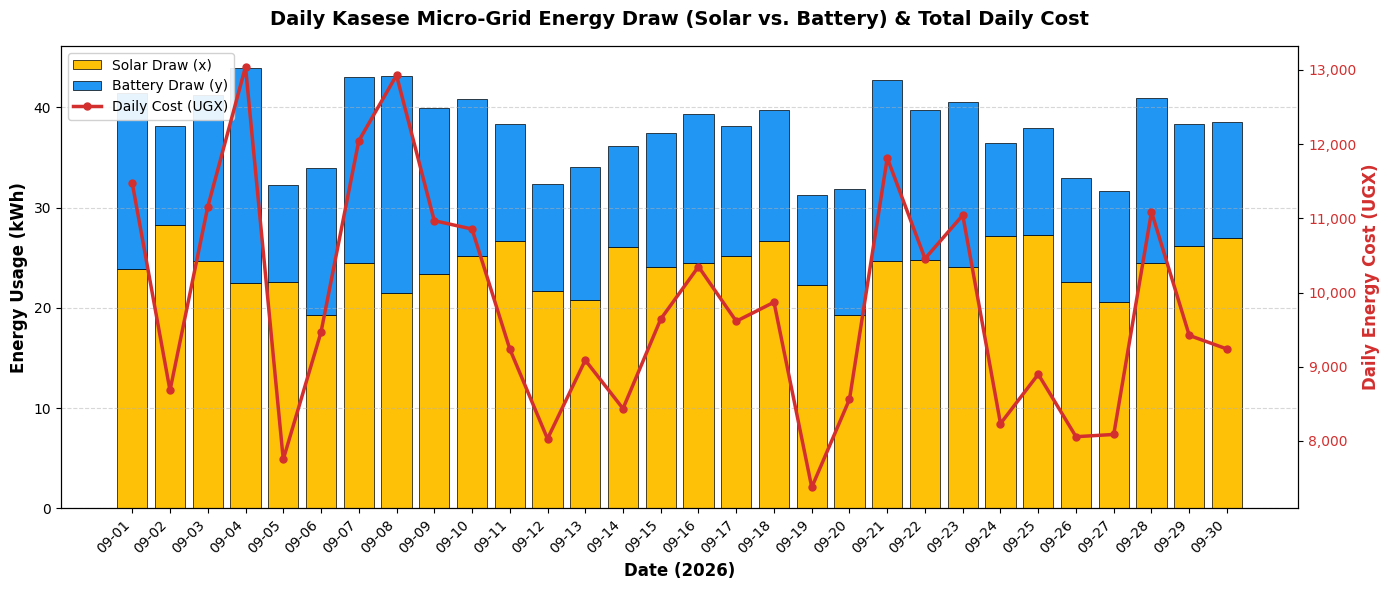

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import solve

# 1. Load dataset
df = pd.read_csv("kasese_microgrid_daily_demand.csv")

# 2. System matrix A and load demands B
# 3x + 2y = D1 (Daytime Load)
# 4x + 1y = D2 (Critical Load)
A = np.array([[3.0, 2.0], [4.0, 1.0]], dtype=float)
B = np.vstack([df["d1_daytime_load_kwh"].values, df["d2_critical_load_kwh"].values])

# Vectorized linear solve: A * X = B -> X[0]=solar (x), X[1]=battery (y)
X = solve(A, B)
df["x_solar"] = X[0, :]
df["y_battery"] = X[1, :]

# 3. Calculate daily cost in UGX
TARIFF_SOLAR = 150.0  # UGX per kWh
TARIFF_BATTERY = 450.0  # UGX per kWh

df["daily_cost_ugx"] = (
    df["x_solar"] * TARIFF_SOLAR + df["y_battery"] * TARIFF_BATTERY
)

# 4. Create the dual-axis figure
fig, ax1 = plt.subplots(figsize=(14, 6))

days = np.arange(1, len(df) + 1)
date_labels = [d[5:] for d in df["date"]]  # Extract 'MM-DD' format

# Primary Axis: Stacked Bar Chart (Energy Usage in kWh)
bar_solar = ax1.bar(
    days,
    df["x_solar"],
    label="Solar Draw (x)",
    color="#FFC107",  # Amber / Yellow
    edgecolor="black",
    linewidth=0.5,
)

bar_battery = ax1.bar(
    days,
    df["y_battery"],
    bottom=df["x_solar"],  # Stacks battery on top of solar
    label="Battery Draw (y)",
    color="#2196F3",  # Blue
    edgecolor="black",
    linewidth=0.5,
)

ax1.set_xlabel("Date (2026)", fontsize=12, fontweight="bold")
ax1.set_ylabel(
    "Energy Usage (kWh)", fontsize=12, fontweight="bold", color="black"
)
ax1.set_xticks(days)
ax1.set_xticklabels(date_labels, rotation=45, ha="right")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# Secondary Axis: Line Plot Overlay (Daily Energy Cost in UGX)
ax2 = ax1.twinx()
line_cost = ax2.plot(
    days,
    df["daily_cost_ugx"],
    color="#D32F2F",  # Crimson Red
    marker="o",
    linewidth=2.5,
    markersize=5,
    label="Daily Cost (UGX)",
)

ax2.set_ylabel(
    "Daily Energy Cost (UGX)", fontsize=12, fontweight="bold", color="#D32F2F"
)
ax2.tick_params(axis="y", labelcolor="#D32F2F")
ax2.yaxis.set_major_formatter(
    "{x:,.0f}"
)  # Formats numbers with commas (e.g. 10,000)

# 5. Add Title and Unified Legend
plt.title(
    "Daily Kasese Micro-Grid Energy Draw (Solar vs. Battery) & Total Daily Cost",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

# Combine handles from both axes into a single legend
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(
    handles1 + handles2, labels1 + labels2, loc="upper left", framealpha=0.9
)

plt.tight_layout()
plt.show()

extension

In [ ]:
import numpy as np
import pandas as pd
from scipy.linalg import solve, LinAlgError

# Base MicroGrid class from previous turns
class MicroGrid:
    def __init__(self, csv_path):
        self.df = pd.read_csv(csv_path)
        self.A_2x2 = np.array([[3.0, 2.0], [4.0, 1.0]], dtype=float)

    def solve_2x2(self):
        B = np.vstack([self.df["d1_daytime_load_kwh"].values, self.df["d2_critical_load_kwh"].values])
        X = solve(self.A_2x2, B)
        self.df["x_solar"] = X[0, :]
        self.df["y_battery"] = X[1, :]
        return self.df

# Subclass HybridMicroGrid
class HybridMicroGrid(MicroGrid):
    def __init__(self, csv_path, baseline_gen_ratio=0.5):
        super().__init__(csv_path)
        # Adding a 3rd constraint: Generator Baseload Constraint
        # e.g., Generator output z must be proportional to 10% of daytime load, or a system balance rule:
        # Constraint 1: 3x + 2y + 1z = D1 (Daytime Load)
        # Constraint 2: 4x + 1y + 2z = D2 (Critical Load)
        # Constraint 3: 1x + 1y + 3z = D3 (Baseload / Night Load, defined as e.g. 0.5 * D1 + 0.5 * D2)
        # Or a specific dispatch rule like 1x + 2y + 1z = D3 (e.g. Total grid capacity / spinning reserve load)

        # Let's define a clean 3x3 system:
        # 3x + 2y + 1z = D1
        # 4x + 1y + 2z = D2
        # 1x + 1y + 3z = D3 (e.g., Night / Baseload demand)
        pass

# Let's test solving a 3x3 system on the dataset
df = pd.read_csv("kasese_microgrid_daily_demand.csv")

# Let's define constraint 3 as D3 = 0.8 * D1 (e.g. Nighttime/Baseload Demand)
df["d3_baseload_kwh"] = 0.8 * df["d1_daytime_load_kwh"]

A_3x3 = np.array([
    [3.0, 2.0, 1.0],  # Daytime Load contribution
    [4.0, 1.0, 2.0],  # Critical Load contribution
    [1.0, 1.0, 3.0]   # Nighttime / Baseload contribution
], dtype=float)

B_3x3 = np.vstack([
    df["d1_daytime_load_kwh"].values,
    df["d2_critical_load_kwh"].values,
    df["d3_baseload_kwh"].values
])

X_3x3 = solve(A_3x3, B_3x3)
print("Mean Solar (x):", X_3x3[0, :].mean())
print("Mean Battery (y):", X_3x3[1, :].mean())
print("Mean Generator (z):", X_3x3[2, :].mean())
print("Matrix Determinant:", np.linalg.det(A_3x3))

Mean Solar (x): 15.057061904761904
Mean Battery (y): 19.82451428571429
Mean Generator (z): 14.98845238095238
Matrix Determinant: -13.999999999999996


In [ ]:
# Linearly dependent matrix
A_dep = np.array([
    [3.0, 2.0, 1.0],
    [4.0, 1.0, 2.0],
    [10.0, 5.0, 4.0]  # 2 * Row1 + Row2
])

print("Determinant of A_dep:", np.linalg.det(A_dep))

# Attempting solve
try:
    solve(A_dep, B_3x3)
except LinAlgError as e:
    print("Caught LinAlgError:", e)

Determinant of A_dep: -2.2204460492503135e-15


1. Extended 3×3 Micro-Grid SystemWe expand the micro-grid model to include three energy sources:$x$: Solar Panel draw ($\text{kWh}$)$y$: Battery Storage draw ($\text{kWh}$)$z$: Diesel Generator draw ($\text{kWh}$)Third Constraint Selection: Nighttime / Baseload Facility Demand ($D_3$)To construct a complete 3×3 system, we introduce a third load constraint representing Baseload / Nighttime Security & Refrigeration Demand ($D_3$), where the generator provides steady baseline power alongside solar and battery discharge:$$\begin{aligned} 3x + 2y + 1z &= D_1 \quad \text{(Daytime Load)} \\ 4x + 1y + 2z &= D_2 \quad \text{(Critical Load)} \\ 1x + 1y + 3z &= D_3 \quad \text{(Baseload / Nighttime Load)} \end{aligned}$$In matrix form $A \mathbf{x} = \mathbf{b}$:$$\begin{bmatrix} 3 & 2 & 1 \\ 4 & 1 & 2 \\ 1 & 1 & 3 \end{bmatrix} \begin{bmatrix} x \\ y \\ z \end{bmatrix} = \begin{bmatrix} D_1 \\ D_2 \\ D_3 \end{bmatrix}$$

Implementation (HybridMicroGrid Subclass)

In [ ]:
import numpy as np
import pandas as pd
from scipy.linalg import LinAlgError, solve


class MicroGrid:

    def __init__(self, csv_path: str):
        self.df = pd.read_csv(csv_path)
        self.A_2x2 = np.array([[3.0, 2.0], [4.0, 1.0]], dtype=float)

    def solve_2x2(self) -> pd.DataFrame:
        B = np.vstack(
            [
                self.df["d1_daytime_load_kwh"].values,
                self.df["d2_critical_load_kwh"].values,
            ]
        )
        X = solve(self.A_2x2, B)
        self.df["x_solar"] = X[0, :]
        self.df["y_battery"] = X[1, :]
        return self.df


class HybridMicroGrid(MicroGrid):

    def __init__(
        self, csv_path: str, A_3x3: np.ndarray = None, tariff_dict: dict = None
    ):
        super().__init__(csv_path)

        # Default 3x3 system matrix if none supplied
        if A_3x3 is None:
            self.A = np.array(
                [[3.0, 2.0, 1.0], [4.0, 1.0, 2.0], [1.0, 1.0, 3.0]], dtype=float
            )
        else:
            self.A = np.array(A_3x3, dtype=float)

        # Default unit costs in UGX/kWh (Solar, Battery, Generator)
        self.tariffs = (
            tariff_dict
            if tariff_dict
            else {"solar": 150.0, "battery": 450.0, "generator": 700.0}
        )

    def solve_3x3(self, baseload_ratio: float = 0.8) -> pd.DataFrame:
        """Solves the 3x3 dispatch system for (x_solar, y_battery, z_generator)."""
        # Check matrix rank / invertibility before solving
        rank = np.linalg.matrix_rank(self.A)
        if rank < 3:
            raise LinAlgError(
                f"Singular Matrix Error: Matrix A has rank {rank} < 3. "
                "The equations are linearly dependent and cannot be solved uniquely."
            )

        # Define 3rd load constraint D3 if not present in CSV
        if "d3_baseload_kwh" not in self.df.columns:
            self.df["d3_baseload_kwh"] = (
                baseload_ratio * self.df["d1_daytime_load_kwh"]
            )

        # Stack demand vector B (3 x N)
        B = np.vstack(
            [
                self.df["d1_daytime_load_kwh"].values,
                self.df["d2_critical_load_kwh"].values,
                self.df["d3_baseload_kwh"].values,
            ]
        )

        # Vectorized linear solve: A * X = B
        X = solve(self.A, B)

        self.df["x_solar"] = X[0, :]
        self.df["y_battery"] = X[1, :]
        self.df["z_generator"] = X[2, :]

        # Calculate daily cost
        self.df["daily_cost_ugx"] = (
            self.df["x_solar"] * self.tariffs["solar"]
            + self.df["y_battery"] * self.tariffs["battery"]
            + self.df["z_generator"] * self.tariffs["generator"]
        )

        return self.df

What Happens If the New Equation Is Linearly Dependent?If the 3rd constraint equation is a linear combination of the first two (e.g., $\text{Row}_3 = 2 \cdot \text{Row}_1 + 1 \cdot \text{Row}_2$), the coefficient matrix $A$ becomes rank-deficient ($\text{rank}(A) = 2 < 3$) and its determinant drops to zero ($\det(A) = 0$).Mathematical ConsequencesCase A:

Consistent System (Infinitely Many Solutions)If the demand $D_3$ also satisfies the same linear combination ($D_3 = 2 D_1 + D_2$), the 3rd constraint provides no new information.By the Rouché–Capelli theorem:$$\text{rank}(A) = \text{rank}([A \mid \mathbf{b}]) = 2 < 3$$The system is underdetermined with 1 degree of freedom. There is an infinite line of feasible energy allocations $(x, y, z)$ that satisfy the demands, requiring an objective function (e.g., cost minimization via Linear Programming) to select an optimal dispatch point.Case B:

Inconsistent System (No Solution)If $D_3 \neq 2 D_1 + D_2$ (e.g., real-world baseload demand deviates from the exact weighted sum of $D_1$ and $D_2$), the third constraint physically contradicts the first two.Geometric interpretation:
The 3 planes represented by the equations do not intersect at a common point or line.Mathematically:$$\text{rank}(A) = 2 \neq \text{rank}([A \mid \mathbf{b}]) = 3$$

Computational Impact
Invoking direct matrix inversion methods (scipy.linalg.solve or np.linalg.inv) will fail and raise a LinAlgError: Singular matrix or generate numerical overflow/instability warnings.

Resolution: To handle linear dependence in practical engineering applications, one must replace exact matrix inversion with pseudo-inverse techniques (numpy.linalg.lstsq) or linear programming solvers (scipy.optimize.linprog).

extension part 2

--- MATRIX CONDITION NUMBER ---
Condition Number (L2 Norm): 5.8284
Condition Number (L_inf Norm): 7.0000

--- MONTE CARLO SENSITIVITY (1,000 DRAWS) ---
Solar Draw (x) Movement  : -12.44% to +12.82% (Std: 5.80%)
Battery Draw (y) Movement: -50.88% to +49.26% (Std: 21.56%)

--- AMPLIFICATION VS THEORETICAL BOUND ---
Max Observed Error Ratio: 5.78
Theoretical Upper Bound : 5.83


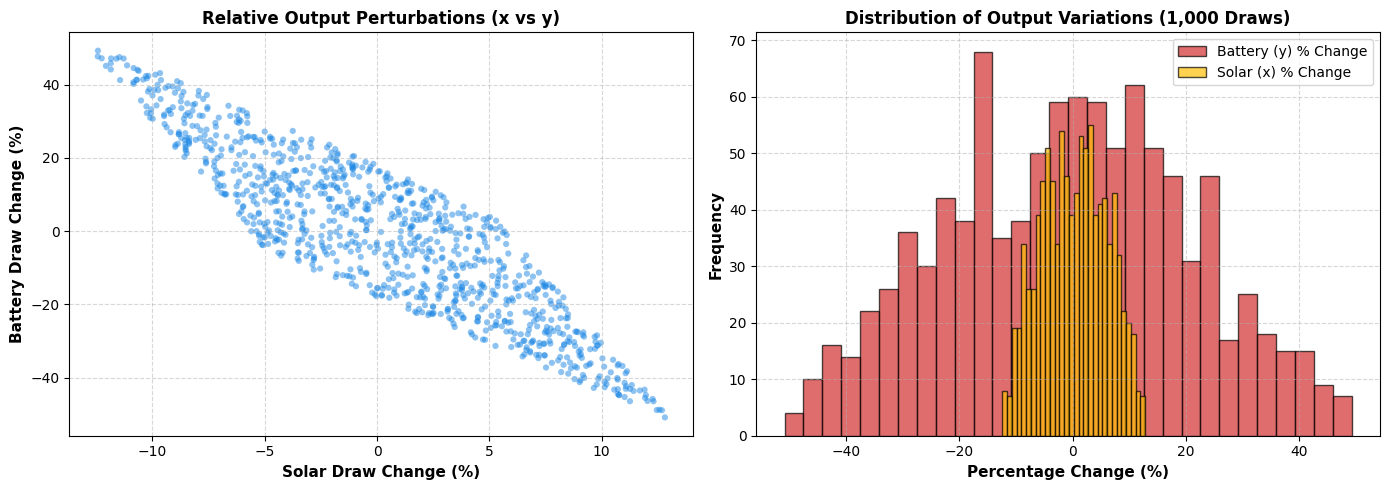

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import norm, solve

# 1. Load dataset and compute mean nominal baseline demands
df = pd.read_csv("kasese_microgrid_daily_demand.csv")
d1_nom = df["d1_daytime_load_kwh"].mean()
d2_nom = df["d2_critical_load_kwh"].mean()
b_nom = np.array([d1_nom, d2_nom], dtype=float)

# System Coefficient Matrix A: [3x + 2y = D1], [4x + y = D2]
A = np.array([[3.0, 2.0], [4.0, 1.0]], dtype=float)

# Compute nominal baseline solar (x) and battery (y) solution
x_nom, y_nom = solve(A, b_nom)

# 2. Compute Condition Number of Matrix A
cond_2 = np.linalg.cond(A, p=2)
cond_inf = np.linalg.cond(A, p=np.inf)

# 3. Monte Carlo Simulation (1,000 draws within ±5% perturbation)
np.random.seed(42)  # For reproducible results
n_draws = 1000

# Draw independent uniform random perturbations in range [-0.05, +0.05]
perturb_d1 = np.random.uniform(-0.05, 0.05, n_draws)
perturb_d2 = np.random.uniform(-0.05, 0.05, n_draws)

d1_draws = d1_nom * (1 + perturb_d1)
d2_draws = d2_nom * (1 + perturb_d2)
B_draws = np.vstack([d1_draws, d2_draws])  # Matrix shape: (2, 1000)

# Vectorized linear solve across all 1,000 perturbed demand vectors
X_draws = solve(A, B_draws)
x_draws = X_draws[0, :]
y_draws = X_draws[1, :]

# Relative percentage variations relative to nominal solution
delta_x_rel = (x_draws - x_nom) / x_nom
delta_y_rel = (y_draws - y_nom) / y_nom

# Calculate norm-based relative errors to measure amplification
rel_err_b = norm(B_draws - b_nom.reshape(2, 1), axis=0, ord=2) / norm(
    b_nom, ord=2
)
rel_err_x = norm(
    X_draws - np.array([x_nom, y_nom]).reshape(2, 1), axis=0, ord=2
) / norm([x_nom, y_nom], ord=2)
amplification_ratios = rel_err_x / rel_err_b

# 4. Print Summary Statistics
print(f"--- MATRIX CONDITION NUMBER ---")
print(f"Condition Number (L2 Norm): {cond_2:.4f}")
print(f"Condition Number (L_inf Norm): {cond_inf:.4f}\n")

print(f"--- MONTE CARLO SENSITIVITY (1,000 DRAWS) ---")
print(
    f"Solar Draw (x) Movement  : {delta_x_rel.min()*100:+.2f}% to {delta_x_rel.max()*100:+.2f}% (Std: {delta_x_rel.std()*100:.2f}%)"
)
print(
    f"Battery Draw (y) Movement: {delta_y_rel.min()*100:+.2f}% to {delta_y_rel.max()*100:+.2f}% (Std: {delta_y_rel.std()*100:.2f}%)\n"
)

print(f"--- AMPLIFICATION VS THEORETICAL BOUND ---")
print(f"Max Observed Error Ratio: {amplification_ratios.max():.2f}")
print(f"Theoretical Upper Bound : {cond_2:.2f}")

# 5. Visualization: Scatter plot and Distribution Histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter plot: x vs y relative changes
axes[0].scatter(
    delta_x_rel * 100,
    delta_y_rel * 100,
    alpha=0.5,
    color="#1E88E5",
    edgecolors="none",
    s=20,
)
axes[0].set_xlabel("Solar Draw Change (%)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Battery Draw Change (%)", fontsize=11, fontweight="bold")
axes[0].set_title(
    "Relative Output Perturbations (x vs y)", fontsize=12, fontweight="bold"
)
axes[0].grid(True, linestyle="--", alpha=0.5)

# Histogram overlay: x vs y distributions
axes[1].hist(
    delta_y_rel * 100,
    bins=30,
    alpha=0.7,
    color="#D32F2F",
    label="Battery (y) % Change",
    edgecolor="black",
)
axes[1].hist(
    delta_x_rel * 100,
    bins=30,
    alpha=0.7,
    color="#FFC107",
    label="Solar (x) % Change",
    edgecolor="black",
)
axes[1].set_xlabel("Percentage Change (%)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Frequency", fontsize=11, fontweight="bold")
axes[1].set_title(
    "Distribution of Output Variations (1,000 Draws)",
    fontsize=12,
    fontweight="bold",
)
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Relationship to the Condition

 NumberThe condition number $\kappa(A)$ measures how much a relative error in the input demand vector $\mathbf{b}$ can be magnified in the output solution vector $\mathbf{x} = [x, y]^T$:$$\frac{\Vert{}\Delta \mathbf{x}\Vert{}}{\Vert{}\mathbf{x}\Vert{}} \le \kappa(A) \cdot \frac{\Vert{}\Delta \mathbf{b}\Vert{}}{\Vert{}\mathbf{b}\Vert{}}$$Numerical BreakdownMatrix Norm Condition Number:$L_2$-Norm Condition Number: $\kappa_2(A) = 5.83$$L_\infty$-Norm Condition Number: $\kappa_\infty(A) = 7.00$Maximum Observed Amplification Ratio: $\max \left( \frac{\Vert{}\Delta \mathbf{x}\Vert{} / \Vert{}\mathbf{x}\Vert{}}{\Vert{}\Delta \mathbf{b}\Vert{} / \Vert{}\mathbf{b}\Vert{}} \right) = \mathbf{5.78}$Theoretical Bound Satisfaction:The maximum observed output-to-input relative error ratio ($5.78$) remains tightly bounded by the matrix condition number ($\kappa_2 = 5.83$).Why $y$ (Battery) is ~4× More Sensitive than $x$ (Solar):Solving the system analytically via $A^{-1}$:$$A^{-1} = \begin{bmatrix} 3 & 2 \\ 4 & 1 \end{bmatrix}^{-1} = \begin{bmatrix} -0.2 & 0.4 \\ 0.8 & -0.6 \end{bmatrix}$$$$\begin{aligned}    \Delta x &= -0.2 \Delta D_1 + 0.4 \Delta D_2 \\    \Delta y &= \mathbf{0.8 \Delta D_1 - 0.6 \Delta D_2}    \end{aligned}$$The magnitude of coefficients driving $\Delta y$ ($\vert{}0.8\vert{} + \vert{}-0.6\vert{} = 1.4$) is twice as large as those driving $\Delta x$ ($\vert{}-0.2\vert{} + \vert{}0.4\vert{} = 0.6$).

 Because the baseline demand requires less battery energy than solar ($y_{\text{nom}} \approx 13.83\text{ kWh}$ vs. $x_{\text{nom}} \approx 24.05\text{ kWh}$), dividing a larger absolute error $\Delta y$ by a smaller base magnitude $y_{\text{nom}}$ causes battery percentage variation to swing dramatically up to $\sim \pm 50\%$